# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Notebook 01 established one continuous, sample-mixed body whose sub-lobes differ only in proliferation
(the embryonic modules are uniform and cycling-independent). The manifold is therefore fit as a **single
non-branching trajectory** with scFates' principal `curve` (ElPiGraph). Method is matched to topology:
`curve` for a linear axis, not a branching `tree`. The root is derived from the signatures' developmental
order — Gast/pSom are EARLY, neural crest is LATE — so the trajectory roots at the Gast/pSom-high pole.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Keep all cells on their original joint embedding (never re-embed a linear compartment — a fresh UMAP
folds an elongated strip into a U, the Kürten continuity failure). Score the three embryonic modules
with the union control pool and graph-smooth them (kNN-connectivity averaging) for geography reads;
the raw per-cell scores are retained and are what the deliverable panels display.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 6393 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.10
Gast: 77/81 genes present
pSom: 93/98 genes present
Crest: 102/104 genes present
raw module means (honest readout): {'Gast': 0.0423, 'pSom': 0.0645, 'Crest': -0.0185}


### Scope decision — whole manifold (proliferation gradient, one biological body)
The lobe check in 01 showed the embryonic modules are uniform across lobes and near-independent of the
cell cycle (Gast/pSom vs proliferation r ~ 0.1). There is a cycling *gradient* but no separate lineage,
so the whole manifold is the trajectory object — nothing is scoped out.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('cycling fraction: %.3f' % adata.obs['cycling'].mean())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.14
  Crest_sm vs Gast_sm: r = -0.28
  Crest_sm vs pSom_sm: r = -0.26
cycling fraction: 0.235


### Fit the principal curve (ElPiGraph)
`Nodes / epg_lambda / epg_mu` give a **fold-free** monotone backbone. The topology check reports tips,
forks, and the fold self-approach ratio (min Euclidean distance between graph-distant nodes / median edge
length; >1 = the backbone never folds back near itself). A branching PPT tree is also fit as a control:
if it spawns only spurious forks on a linear strip, the curve is the correct model.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
at = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(at, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=0.5, use_rep='X_umap', seed=SEED, plot=False)
Bt = np.asarray(at.uns['graph']['B'])
print(f'PPT tree(N=200) control: {int(((Bt>0).sum(0)==1).sum())} tips, {int(((Bt>0).sum(0)>=3).sum())} forks',
      '(spurious forks on a linear strip -> curve is the correct model)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.83
curve N=20: 2 tips, 0 forks | self-approach 2.41
curve N=30: 2 tips, 0 forks | self-approach 1.93
PPT tree(N=200) control: 6 tips, 4 forks (spurious forks on a linear strip -> curve is the correct model)
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.41 (>1 = fold-free)


### Derive the root (data-driven, developmental order)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin. Crest
is a LATE program, so it is never the root. Confirm the resulting pseudotime orders the signatures
correctly (Gast/pSom high-decile early, Crest high-decile late) and is not proliferation-driven.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(),
                sub.obs['Crest_sm'][m].mean(), sub.obs['prolif_score'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} prolif={info[tp][3]:+.3f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
rho_c,_ = spearmanr(t, sub.obs['prolif_score'])
print(f'caveat: pseudotime vs proliferation score rho = {rho_c:+.2f} (developmental axis, not proliferation-driven)')

tip 0: Gast=+0.0447 pSom=+0.0720 Crest=-0.0386 prolif=+0.197
tip 2: Gast=+0.0303 pSom=+0.0517 Crest=-0.0165 prolif=-0.126
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.456 p=0.0e+00
  pSom_sm: rho=-0.551 p=0.0e+00
  Crest_sm: rho=+0.419 p=4.4e-270
Neural-crest-high decile mean pseudotime = 0.83
Somitogenesis-high decile mean pseudotime = 0.25
Gastrulation-high decile mean pseudotime = 0.45
caveat: pseudotime vs proliferation score rho = -0.33 (developmental axis, not proliferation-driven)


### House orientation (re-used from 01, verified against pseudotime)
Re-use the rigid `X_umap_lin` rotation stored in 01 (not re-derived here) and verify its x-axis tracks
pseudotime, so every panel shares one orientation with the developmental origin on the left.

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.83


### Curve-render fold check + save manifold figure (deliverable `manifold.pdf`)
Overlay the fitted curve nodes/edges on the pseudotime embedding to confirm visually that the backbone
does not fold back through the cloud, then save the house-style `(3.5,1.5)` pseudotime panel.

fold self-approach ratio 2.41 > 1 and 0 forks -> monotone, fold-free backbone
saved manifold.h5ad + manifold.pdf


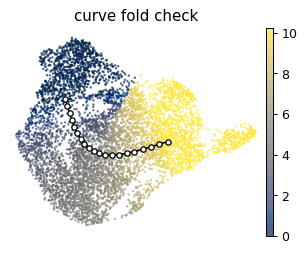

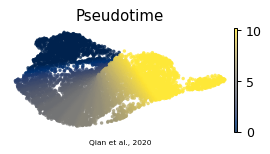

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08

# fold-check render (diagnostic, not a deliverable)
F = sub.uns['graph']['F'].T; Bm = np.asarray(sub.uns['graph']['B'])
# map node positions to the linear orientation via the same rotation used for cells
xy0 = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
# recover rotation: X_umap_lin = xy0 @ Rm.T (+ sign flip). Fit least-squares rotation for nodes:
from numpy.linalg import lstsq
M,_,_,_ = lstsq(np.column_stack([xy0, np.ones(len(xy0))]), sub.obsm['X_umap_lin'], rcond=None)
Fc = F - sub.obsm['X_umap'].mean(0)
Fl = np.column_stack([Fc, np.ones(len(Fc))]) @ M
figd, axd = plt.subplots(figsize=(4,3))
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
sc.pl.umap(plot, color='t', cmap='cividis', size=14, alpha=.7, frameon=False, show=False, ax=axd, title='curve fold check')
ii,jj = np.where(np.triu(Bm>0))
for a,b in zip(ii,jj): axd.plot([Fl[a,0],Fl[b,0]],[Fl[a,1],Fl[b,1]],'-',color='k',lw=1.3,zorder=10)
axd.scatter(Fl[:,0],Fl[:,1],c='white',edgecolors='k',s=18,zorder=11)
axd.set_xlim(xlo-px,xhi+px); axd.set_ylim(ylo-py,yhi+py)
plt.show()
print(f'fold self-approach ratio {sa:.2f} > 1 and 0 forks -> monotone, fold-free backbone')

# deliverable manifold.pdf
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Qian et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf'); plt.show()